In [2]:
import numpy as np
from matplotlib import pyplot as plt

数据初始化与维度变换：

In [ ]:
grayscale_image = np.random.randint(0,256,size=(200,300))
color_image = np.repeat(grayscale_image[:,:,np.newaxis],3,axis=-1)
print(color_image)

基于矩阵乘法的滤镜实现：

In [4]:
sepia_matrix = np.array([
    [0.393, 0.769, 0.189],
    [0.349, 0.686, 0.168],
    [0.272, 0.534, 0.131]
])

new_color_image = color_image @ sepia_matrix
new_color_image = np.clip(new_color_image,0,255)

基于元素级运算的色彩增强：

In [ ]:
alpha = 1.5
sturate_image = new_color_image
L = 0.299*sturate_image[:,:,0]+0.587*sturate_image[:,:,1]+0.114*sturate_image[:,:,2]
print(L)
L = np.repeat(L[:,:,np.newaxis],3,axis=-1)
print(L)
sturate_image = L - alpha*(sturate_image - L)
#clip
sturate_image = np.clip(sturate_image,0,255)
#sturate 

利用数组切片添加特效：

In [46]:
color_image_left = np.linspace(0,color_image[:,0,:],30)
color_image_right = np.linspace(color_image[:,-1,:],255,30)
color_image_left = np.swapaxes(color_image_left,0,1)
color_image_right = np.swapaxes(color_image_right,0,1)
print(color_image_right.shape,color_image_left.shape,color_image.shape)
color_image = np.concatenate([color_image_left,color_image,color_image_right],axis=1)
#200,30,3

(200, 30, 3) (200, 30, 3) (200, 300, 3)


oop方式画图

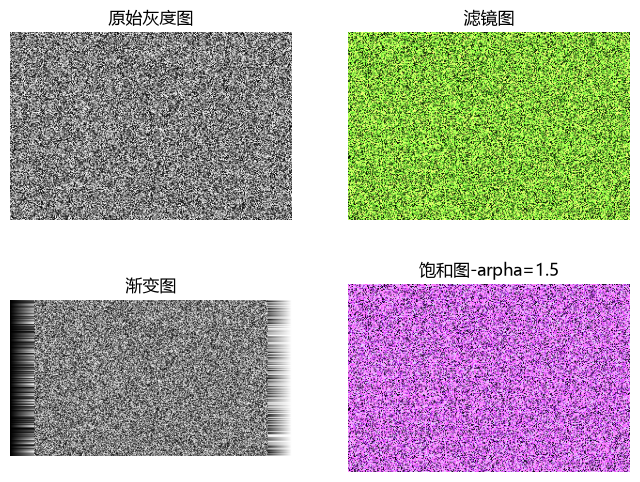

In [69]:
#中文
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig,axes = plt.subplots(2,2,figsize = (8,6))
axes[0,0].imshow(grayscale_image,cmap="gray")
axes[0,0].set_title('原始灰度图')
axes[1,0].imshow(color_image.astype(np.uint8))
axes[1,0].set_title('渐变图')
axes[0,1].imshow(new_color_image.astype(np.uint8))
axes[0,1].set_title('滤镜图')
axes[1,1].imshow(sturate_image.astype(np.uint8))
axes[1,1].set_title('饱和图-arpha=1.5')
for i in range(2):
    for o in range(2):
        axes[i,o].axis('off')
plt.show() 
